# 05 – Neural network (MLP) + distillation (pion)

## 1. Introduction

Instead of formulas, here a **neural network** learns the shape, without a predefined functional form.
For every momentum, the network outputs a full probability map on the $(z', r)$ grid. It is trained with the same detector convolution and
likelihood as the GFlash formula (01), so the two are directly comparable.

**How does the MLP ("neural field") work?** The network is queried separately for every grid cell: *"what is the density at depth $z'$,
distance $r$, momentum $p$?"* The network's answers ($z'$, $r$, $\ln p$ and their sinusoidal features → $n_L$ hidden layers, $H$ neurons each → one number)
are turned into a probability map by a softmax. It acts like a **flexible, malleable map**: the network can take any smooth shape
the data demand.

**How large should the network be?** For the formulas, the degree of the $\ln p$ polynomial was chosen on the validation set (01, 4b). Here the same
protocol selects the **architecture**: several (layers, neurons) pairs are trained, and we keep the smallest one beyond which
larger networks no longer improve detectably (1-SE rule). This demonstrates that the network capacity is **sufficient**.

**Distillation (symbolic regression):** finally, the trained network is "translated" into an analytic formula: several formula families are fitted to the network maps,
and the simplest sufficiently accurate one is kept. This condenses the flexibility of the network into an interpretable formula with few parameters.

**Unified comparison (section 7):** at the end, the previous shapes (GFlash $r_{95}$, envelope, drop) and the two new shapes
(MLP $r_{95}$, distilled formula $r_{95}$) are compared with the same metric and on the same plots as in notebook 03.

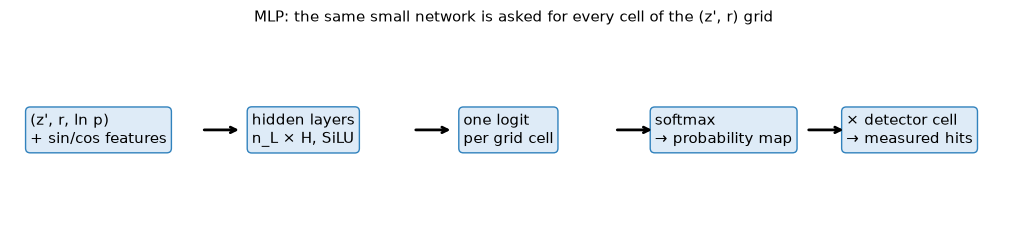

In [1]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(13, 2.6)); ax.axis("off")
boxes = [("(z', r, ln p)\n+ sin/cos features", 0.02), ("hidden layers\nn_L × H, SiLU", 0.24), ("one logit\nper grid cell", 0.45),
         ("softmax\n→ probability map", 0.64), ("× detector cell\n→ measured hits", 0.83)]
for txt, x in boxes:
    ax.text(x, 0.5, txt, ha="left", va="center", fontsize=11, bbox=dict(boxstyle="round", fc="#deebf7", ec="#3182bd"))
for x in (0.19, 0.40, 0.60, 0.79):
    ax.annotate("", xy=(x + 0.04, 0.5), xytext=(x, 0.5), arrowprops=dict(arrowstyle="->", lw=2))
ax.set_title("MLP: the same small network is asked for every cell of the (z', r) grid", fontsize=11)
plt.show()

## 2. Loading the data

In [ ]:
PARTICLES = ['pion']
# Paths come from sfm.paths (shape-form-martin/src/sfm/paths.py): the Parquet copy of the data in
# ../shape-form-original/data/ (override: SFM_DATA_DIR) and the output directory results/ (override: SFM_RESULTS_DIR).
import os
import sys
sys.path.insert(0, os.path.abspath("src"))                    # run from shape-form-martin/
from sfm import paths
DATA_DIR = paths.rel_to(paths.DATA_DIR, os.getcwd()) + "/"     # where the data file is
FILE_PATTERN = paths.FILE_PATTERN                              # the Parquet file (the CSV is not used)
OUT_DIR = paths.rel_to(paths.RESULTS_DIR, os.getcwd())         # models and exports are stored here

# common.py is the importable version of 00_common.ipynb. This block replaces `%run -i ./00_common.ipynb`.
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Markdown, display

import common
common.configure(data_dir=DATA_DIR, out_dir=OUT_DIR, file_pattern=FILE_PATTERN)
from common import (DEVICE, DZ, LOG_VOL, N_R, N_Z, R_EDGES, R_MAX, RC, RR, Z_EDGES, Z_MAX, Z_MIN, ZC, ZZ,
                    Formula, TableModel, bodies_3d, distill, export, fold, formula_curves, iso_radius, load_data,
                    profile_plot, revolve, sample_folded, select_architecture, shape_map, test_nll)

In [3]:
DATA = {}
for particle in PARTICLES:
    df, geo, DATA[particle] = load_data(particle)
    print(f"\n===== {particle} =====")
    df.info()
    display(df.describe().T)
    display(df.head())

pion: 99689 events, geometry {'layer': 20.5, 'cell': 48.59999999999991, 'z_back': 4882.15}, split train 69783, val 14950, test 14956

===== pion =====
<class 'pandas.DataFrame'>
RangeIndex: 49110973 entries, 0 to 49110972
Data columns (total 21 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   event_number                int64  
 1   cellID                      int64  
 2   x                           float64
 3   y                           float64
 4   z                           float64
 5   x_local                     float64
 6   y_local                     float64
 7   z_local                     float64
 8   x_trans                     float64
 9   y_trans                     float64
 10  z_trans                     float64
 11  energy                      float64
 12  earliest_contribution_time  float64
 13  incoming_momentum           float64
 14  incoming_theta              float64
 15  incoming_phi                float64
 16  in

,count,mean,std,min,25%,50%,75%,max
event_number,49110973.0,1.050066e+05,6.065561e+04,0.000000e+00,5.237000e+04,1.050170e+05,1.575570e+05,2.099970e+05
cellID,49110973.0,2.090493e+09,1.473656e+09,4.212000e+03,7.221679e+08,1.753932e+09,3.309956e+09,5.063386e+09
x,49110973.0,3.218513e+00,1.306847e+03,-2.596035e+03,-1.036428e+03,3.040900e+01,1.041428e+03,2.601035e+03
y,49110973.0,-2.283059e+00,1.307162e+03,-2.599800e+03,-1.036200e+03,2.620000e+01,1.036200e+03,2.599800e+03
z,49110973.0,4.091779e+03,2.837958e+02,3.662400e+03,3.867400e+03,4.051900e+03,4.277400e+03,4.871900e+03
x_local,49110973.0,-3.666150e+01,2.144154e+02,-4.968845e+03,-1.326416e+02,-2.568672e+01,6.705917e+01,4.137740e+03
y_local,49110973.0,2.505265e-01,2.130792e+02,-3.721291e+03,-1.014420e+02,0.000000e+00,1.017206e+02,3.125906e+03
z_local,49110973.0,4.471790e+02,3.021535e+02,-2.985229e+03,2.110727e+02,3.987507e+02,6.431534e+02,2.933382e+03
x_trans,49110973.0,7.058134e-01,2.452876e+02,-4.806044e+03,-1.353739e+02,0.000000e+00,1.376407e+02,5.016641e+03
y_trans,49110973.0,-2.141510e-01,2.452217e+02,-5.128854e+03,-1.368652e+02,0.000000e+00,1.354339e+02,4.766881e+03


,event_number,cellID,x,y,z,x_local,y_local,z_local,x_trans,y_trans,...,energy,earliest_contribution_time,incoming_momentum,incoming_theta,incoming_phi,incoming_momentum_bin,particle_type,is_secondary,parent_type,daughter_type
0,32577,2844239732,-1233.912964,-377.799988,4379.899902,174.624418,-6.043664,785.270612,-350.431969,-97.833189,...,1.627338e-05,37.407822,18.368912,0.250428,-2.852734,18,proton,1,neutron,NaN
1,117646,3947026804,128.524002,1440.199951,4625.899902,-1151.930652,178.009222,427.047158,-373.923903,-687.640495,...,1.829786e-05,35.721050,1.610262,0.546492,1.302170,1,neutron,1,neutron,NaN
2,113305,2281791604,-430.761993,2094.800049,4359.399902,172.598498,-397.387051,833.346339,177.570017,604.013841,...,7.539088e-05,11227.231445,18.748279,0.406894,1.967967,18,gamma,1,neutron,NaN
3,141634,4387483508,-2041.468018,1137.199951,4031.399902,-93.626889,3.687866,374.588895,-100.943970,52.399902,...,1.757939e-07,195.216415,10.812306,0.543763,2.630352,10,neutron,1,neutron,gamma;gamma;gamma
4,132530,3913543284,-1892.254028,1036.199951,4420.899902,-338.212858,507.919669,679.356918,-359.455044,-359.674814,...,1.385399e-08,3079.680420,16.386311,0.493974,2.404347,16,neutron,1,neutron,NaN


## 3. The model

### What do we fit, and what affects training?

**Input:** only $\ln p$ (`incoming_momentum`); the network additionally receives the grid cell position ($z'$, $r$ and their sine/cosine features).
**Output:** the full $(z', r)$ map. Training minimises the same likelihood as for the formulas, so the fitted features are the same:
- $z'$ = `z_local`, $r$ = `hypot(x_local, y_local)`, weight `energy` (normalised per event), grouped by `event_number`.
- **Affected by:** the detector convolution (`incoming_theta`, `incoming_phi`, cell size), the back-face truncation ($z_b$ from the `z`, `z_trans` columns), the cuts.

**What differs from the formulas:**
- There is no prescribed functional form, so the shape is limited by **the grid resolution and the network architecture**. The number of layers ($n_L$) and
  neurons ($H$) are chosen in section 4; the number of frequencies is fixed (4).
- **Smoothness penalty** (`smooth=1e-4`): the second difference of $\log P$ along depth. It sets the "stiffness" of the network.
- **Beyond the back face** and **below the cell scale** the data do not constrain the network: there the output is set by the architecture and the penalty (artefacts are possible).
- Training: `epochs=60`, `lr=3e-3`, Adam, early stopping on the validation NLL (`patience=15`).

In [11]:
class FieldModel(nn.Module):
    """MLP(z', r, ln p) -> logit for every grid cell -> softmax."""

    def __init__(self, hidden=64, n_layers=3, n_freq=4):
        super().__init__()
        zn = (ZZ - Z_MIN) / (Z_MAX - Z_MIN) * 2 - 1          # depth scaled to [-1, 1]
        rn = torch.sqrt(RR / R_MAX)                            # radius, stretched near the axis
        feats = [zn, rn]
        for k in range(1, n_freq + 1):                         # sin/cos features: help to learn sharp structures
            feats += [torch.sin(math.pi * k * zn), torch.cos(math.pi * k * zn),
                      torch.sin(math.pi * k * rn), torch.cos(math.pi * k * rn)]
        self.register_buffer("static", torch.stack(feats, -1))
        layers, d = [], self.static.shape[-1] + 1
        for _ in range(n_layers):
            layers += [nn.Linear(d, hidden), nn.SiLU()]
            d = hidden
        self.mlp = nn.Sequential(*layers, nn.Linear(d, 1))

    def forward(self, lnp):
        x = torch.cat([self.static[None].expand(len(lnp), -1, -1, -1),
                       (lnp / 3)[:, None, None, None].expand(-1, N_Z, N_R, 1)], -1)
        logits = self.mlp(x).squeeze(-1)
        return F.log_softmax(logits.reshape(len(lnp), -1), 1).reshape(len(lnp), N_Z, N_R)


make_model = lambda hidden=64, n_layers=3: FieldModel(hidden, n_layers).to(DEVICE)
arch_label = lambda cfg: f"L{cfg['n_layers']}xH{cfg['hidden']}"

print("parameters (L3xH64):", sum(p.numel() for p in make_model().parameters()))

parameters (L3xH64): 9665


## 4. Training and architecture selection

Same protocol as the degree selection for the formulas (common notebook, section 7, `select_architecture`):
- **train:** network weights; **validation:** early stopping and architecture selection; **test:** evaluation of the final network only.
- **Rule:** we compute the per-event paired difference relative to the architecture with the lowest validation NLL ($c^*$); the network with the **fewest
  parameters** whose difference is within one standard error is chosen.

The search has two stages (instead of a full grid, to save run time):
1. **Width:** $H \in \{16, 32, 64, 128, 256\}$, with 3 hidden layers.
2. **Depth (4b):** $n_L \in \{1, 2, 3, 4, 5\}$ with the chosen width.

Every network is saved to `results/pion/mlp_L<n_L>xH<H>.pt`; a completed training is only loaded.

**What to look for:** if the chosen network is at the **edge** of the range (largest $H$ or $n_L$), the search must be extended,
because sufficient capacity is not demonstrated. If it is inside and the curve flattens for larger networks, the capacity is saturated.

In [12]:
particle = "pion"
data = DATA[particle]
WIDTHS = [dict(n_layers=3, hidden=h) for h in (16, 32, 64, 128, 256)]
cfg_w, TAB_W, MODELS_W = select_architecture(make_model, WIDTHS, data, particle, "mlp", epochs=60, lr=3e-3, smooth=1e-4, label=arch_label)
display(TAB_W.round(4))

--- L3xH16 ---
epoch    0  train 18.1711  val 18.1449  (7s)
epoch   10  train 18.1208  val 18.1314  (77s)
epoch   20  train 18.1191  val 18.1285  (145s)
epoch   30  train 18.1185  val 18.1275  (215s)
epoch   40  train 18.1183  val 18.1300  (284s)
epoch   41  train 18.1184  val 18.1274  (291s)
--- L3xH32 ---
epoch    0  train 18.1658  val 18.1445  (10s)
epoch   10  train 18.1202  val 18.1306  (108s)
epoch   20  train 18.1190  val 18.1285  (206s)
epoch   30  train 18.1181  val 18.1282  (305s)
epoch   40  train 18.1176  val 18.1302  (402s)
epoch   44  train 18.1175  val 18.1309  (440s)
--- L3xH64 ---
epoch    0  train 18.1564  val 18.1400  (17s)
epoch   10  train 18.1204  val 18.1307  (188s)
epoch   20  train 18.1189  val 18.1281  (360s)
epoch   26  train 18.1184  val 18.1275  (462s)
--- L3xH128 ---
epoch    0  train 18.1523  val 18.1371  (33s)
epoch   10  train 18.1205  val 18.1308  (356s)
epoch   20  train 18.1187  val 18.1279  (681s)


KeyboardInterrupt: 

## 4b. Choosing the number of layers

With the chosen width, the number of layers is varied. The 3-layer network is loaded from the previous step.

--- L1xH32 ---
loaded finished model from results/pion/mlp_L1xH32.pt


--- L2xH32 ---
loaded finished model from results/pion/mlp_L2xH32.pt


--- L3xH32 ---
loaded finished model from results/pion/mlp_L3xH32.pt


--- L4xH32 ---
loaded finished model from results/pion/mlp_L4xH32.pt


--- L5xH32 ---
loaded finished model from results/pion/mlp_L5xH32.pt


lowest validation NLL: L5xH32;  chosen by the 1-SE rule: L4xH32


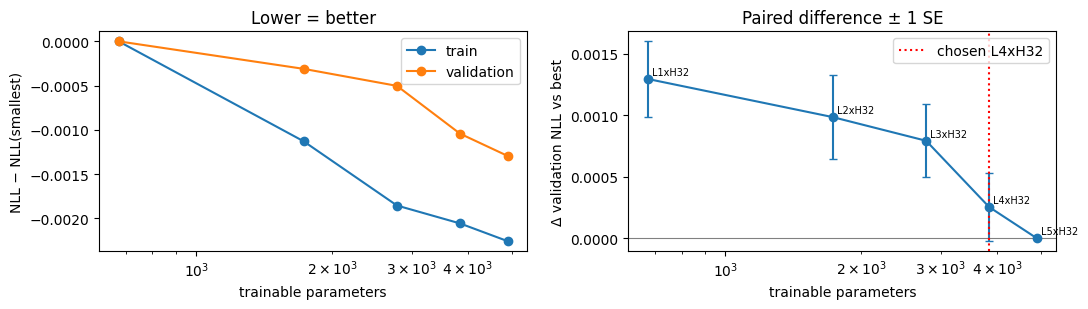

,n_layers,hidden,params,train NLL,val NLL,epochs,Δval vs best,SE,chosen
config,,,,,,,,,
L1xH32,1,32,673,18.1102,18.1201,60,0.0013,0.0003,
L2xH32,2,32,1729,18.1090,18.1198,42,0.0010,0.0003,
L3xH32,3,32,2785,18.1083,18.1196,45,0.0008,0.0003,
L4xH32,4,32,3841,18.1081,18.1191,45,0.0003,0.0003,◀
L5xH32,5,32,4897,18.1079,18.1188,60,0.0000,0.0000,


chosen architecture: L4xH32 | parameters: 3841 | inside the search range: capacity is sufficient


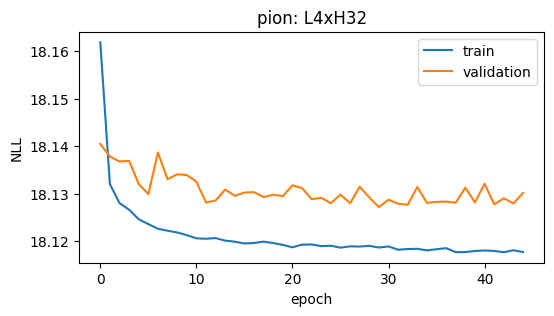

In [6]:
DEPTHS = [dict(n_layers=n, hidden=cfg_w["hidden"]) for n in (1, 2, 3, 4, 5)]
cfg, TAB_D, MODELS_D = select_architecture(make_model, DEPTHS, data, particle, "mlp", epochs=60, lr=3e-3, smooth=1e-4, label=arch_label)
display(TAB_D.round(4))
ARCH_TABLE = pd.concat([TAB_W.assign(stage="width"), TAB_D.assign(stage="depth")])
edge = cfg["hidden"] == max(c["hidden"] for c in WIDTHS) or cfg["n_layers"] == max(c["n_layers"] for c in DEPTHS)
print("chosen architecture:", arch_label(cfg), "| parameters:", int(TAB_D.loc[arch_label(cfg), "params"]),
      "| at the edge of the search range!" if edge else "| inside the search range: capacity is sufficient")

NETS = {particle: MODELS_D[arch_label(cfg)]}
hist = torch.load(f"{OUT_DIR}/{particle}/mlp_{arch_label(cfg)}.pt", weights_only=False)["history"]
plt.figure(figsize=(6, 3)); plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="validation")
plt.title(f"{particle}: {arch_label(cfg)}"); plt.xlabel("epoch"); plt.ylabel("NLL"); plt.legend(); plt.show()

## 5. Distillation

Four formula families ($\{$`gamma`, `plateau`$\} \times \{$`core_tail`, `gauss_exp`$\}$) with first- and second-degree $\ln p$ dependence are fitted
to the maps of the chosen network. We keep the simplest one within 0.005 nat KL of the best.

**Here the formula is fitted to the network maps, not to the data** (KL divergence, 30 $\ln p$ values between the 2–98% quantiles of the training data, without convolution).
The map is used only up to depth $z_{cut}$ (still in front of the back face for 90% of training events). The formula quality is therefore also affected by the network's errors and
artefacts; the test NLL shows the result measured against the data. The result is saved to `results/pion/mlp_formula.pt`.

In [7]:
CANDIDATES = [("gamma", "core_tail"), ("gamma", "gauss_exp"), ("plateau", "core_tail"), ("plateau", "gauss_exp")]
FORMULAS = {}
for particle in PARTICLES:
    print(f"===== {particle} =====")
    path = f"{OUT_DIR}/{particle}/mlp_formula.pt"
    if os.path.exists(path):
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        f = Formula(ck["long"], ck["lat"], ck["degree"]).to(DEVICE)
        f.load_state_dict(ck["state"])
        print("loaded", path)
        display(ck["table"])
    else:
        f, table, z_cut = distill(NETS[particle], DATA[particle]["train"], CANDIDATES, steps=600)
        display(table.sort_values("KL"))
        torch.save({"long": f.long, "lat": f.lat, "degree": f.degree, "state": f.state_dict(), "table": table}, path)
    FORMULAS[particle] = f

===== pion =====
loaded results/pion/mlp_formula.pt


,longitudinal,lateral,degree,params,KL
0,gamma,core_tail,1,15,0.095074
1,gamma,core_tail,2,21,0.085698
2,gamma,gauss_exp,1,15,0.117131
3,gamma,gauss_exp,2,21,0.107919
4,plateau,core_tail,1,19,0.091100
5,plateau,core_tail,2,27,0.083335
6,plateau,gauss_exp,1,19,0.113694
7,plateau,gauss_exp,2,27,0.105801


## 6. Results

**What to look for:**
- **Test NLL:** whether the NLLs of the network and the formula are close. If so, the formula captures almost everything the network learned.
  Reference: the test NLL of the GFlash formula (01); the network must not be worse, otherwise it is not flexible enough or trained poorly.
- **Profiles:** both the network (orange) and the formula (red) should follow the data (black).
- **True shape and 3D:** whether the network shape is smooth. The network may learn small sub-cell artefacts (e.g. a thin spike on the axis),
  because the data do not constrain it there; the formula smooths these out.
- **Formula:** which family won, and how its parameters depend on momentum.

## pion

test NLL  GFlash (01): 18.1563
test NLL  mlp: 18.1221   formula: 18.1634   difference (paired): +0.0413 ± 0.0013


/tmp/ipykernel_325424/1674953462.py:114: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  terms = " ".join(f"{float(v):+.4g}" + ("" if k == 0 else rf"\,{L}" if k == 1 else rf"\,{L}^{k}")


### The distilled formula (gamma × core_tail, degree 2)

$$L \propto s^{\alpha-1}e^{-(\alpha-1)s/t_{max}},\; s=z'-z_0,\; \alpha=1+e^{\mathrm{log\_am1}},\; t_{max}=e^{\mathrm{log\_tmax}}$$

$$T = \frac{p_c}{\pi}\frac{R_C^2}{(r^2+R_C^2)^2}+\frac{1-p_c}{\pi}\frac{R_T^2}{(r^2+R_T^2)^2}$$

| parameter | value, $L=\ln(p/\mathrm{GeV})$ | depth slope (× z'/1000) |
|---|---|---|
| `z0` | $-14.79 -2.783\,L +1.193\,L^2$ | – |
| `log_tmax` | $+3.985 +0.4306\,L -0.04058\,L^2$ | – |
| `log_am1` | $-0.8926 -0.1825\,L +0.07527\,L^2$ | – |
| `log_rc` | $+3.139 +0.05844\,L -0.02831\,L^2$ | +1.293 |
| `log_ratio` | $+1.006 -0.2336\,L +0.0634\,L^2$ | +0.4727 |
| `logit_pc` | $+0.7942 -0.8356\,L +0.2924\,L^2$ | -0.1681 |

Number of parameters: **21**

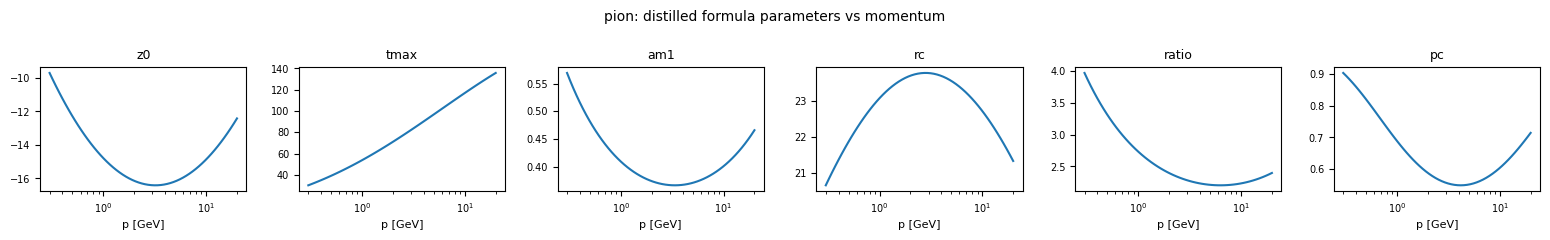

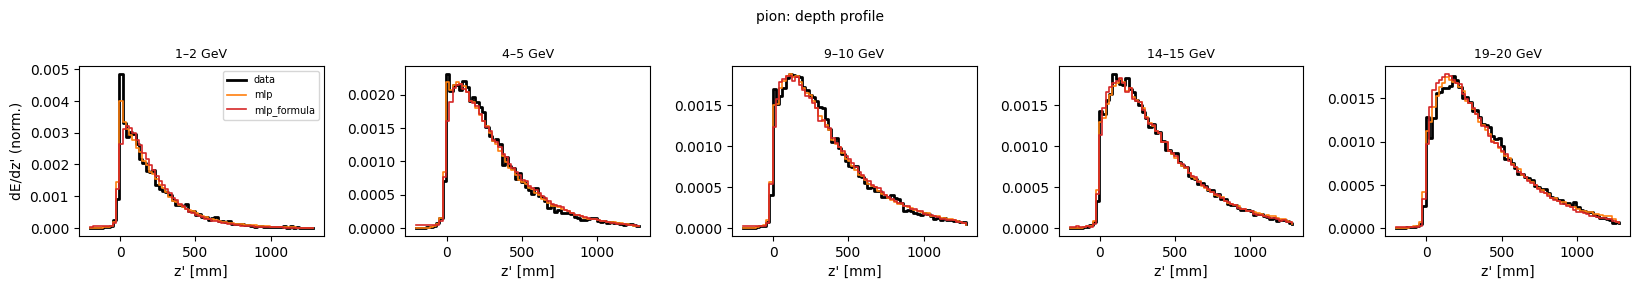

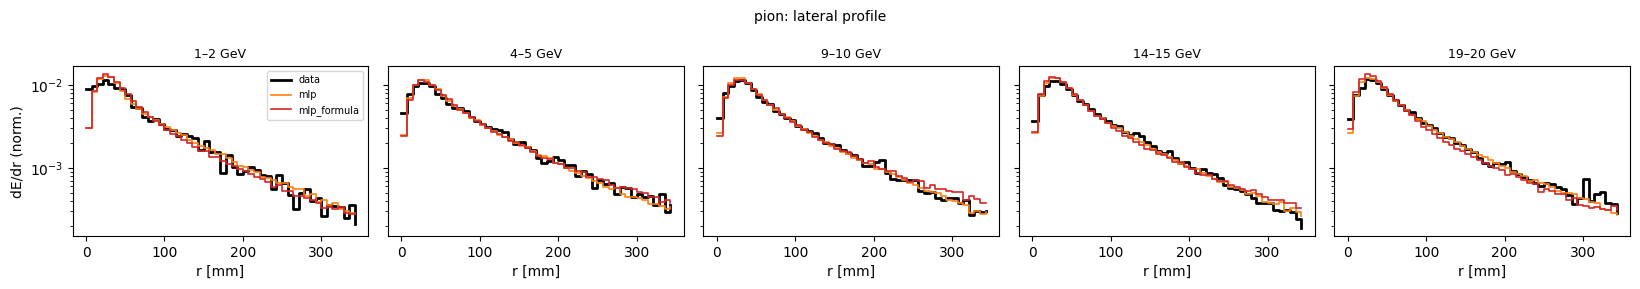

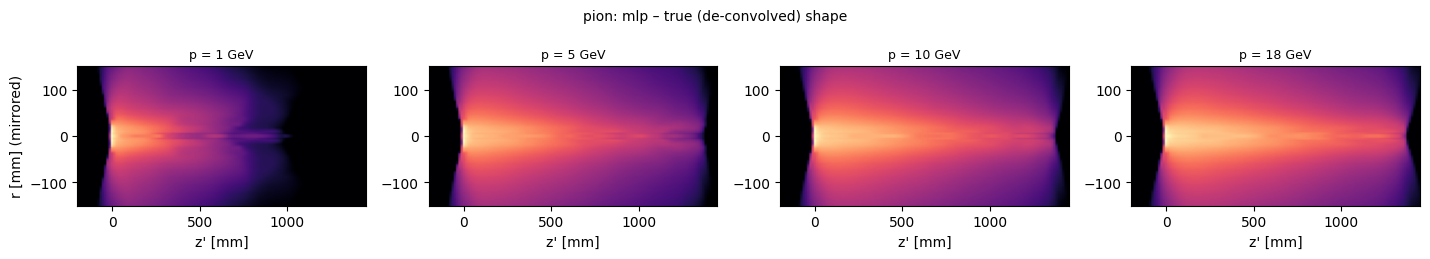

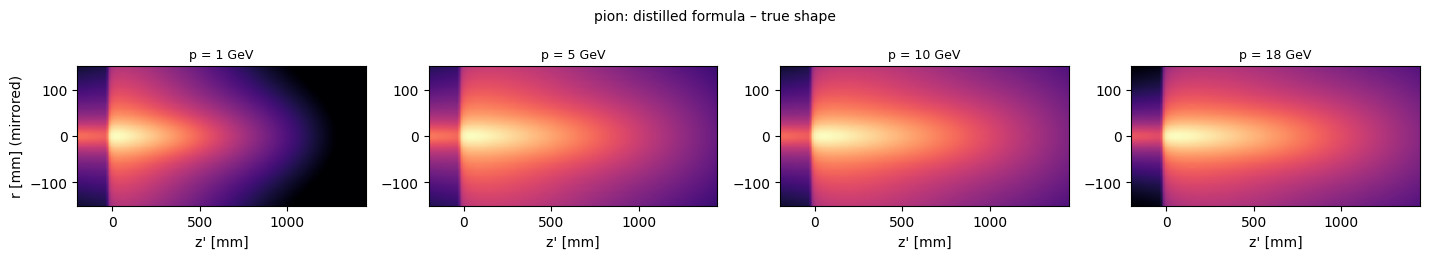

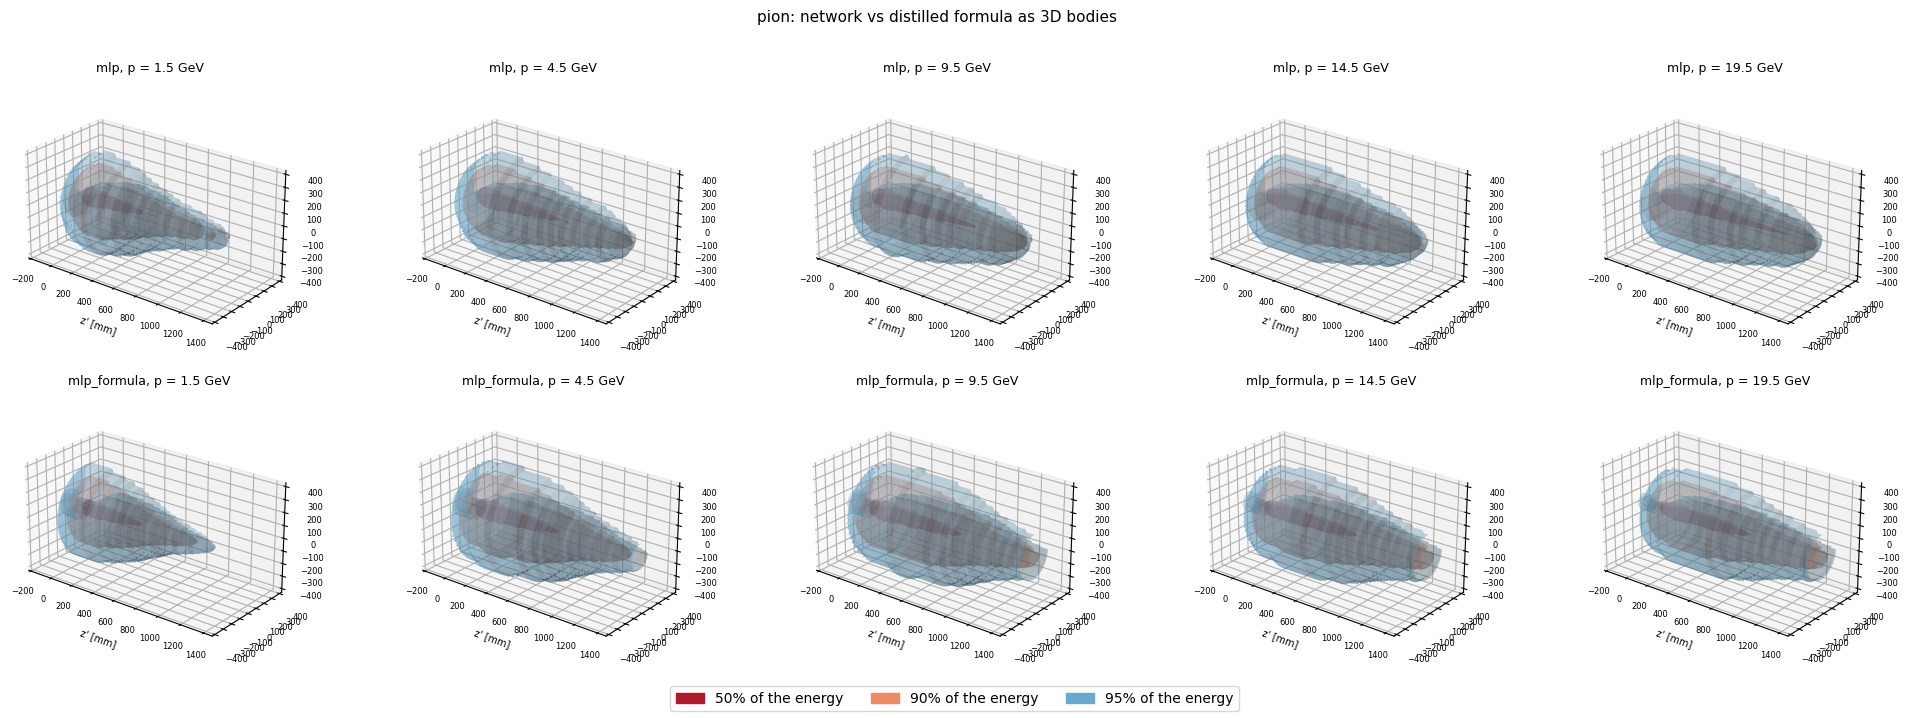

exported pion/mlp: test NLL = 18.1221
exported pion/mlp_formula: test NLL = 18.1634


In [8]:
for particle in PARTICLES:
    display(Markdown(f"## {particle}"))
    data, net, f = DATA[particle], NETS[particle], FORMULAS[particle]
    nll_net, nll_f = test_nll(net, data["test"]), test_nll(f, data["test"])
    gf_path = f"{OUT_DIR}/{particle}/export_gflash.pt"
    if os.path.exists(gf_path):
        print(f"test NLL  GFlash (01): {torch.load(gf_path, weights_only=False)['test_nll'].mean():.4f}")
    d = nll_f - nll_net
    print(f"test NLL  mlp: {nll_net.mean():.4f}   formula: {nll_f.mean():.4f}   "
          f"difference (paired): {d.mean():+.4f} ± {d.std(ddof=1) / np.sqrt(len(d)):.4f}")
    display(Markdown(f.describe(f"The distilled formula ({f.long} × {f.lat}, degree {f.degree})")))
    formula_curves(f, f"{particle}: distilled formula parameters vs momentum")
    hits = data["test"].hits()
    samples = {"mlp": sample_folded(net, data["test"]), "mlp_formula": sample_folded(f, data["test"])}
    profile_plot(hits, samples, "z", f"{particle}: depth profile")
    profile_plot(hits, samples, "r", f"{particle}: lateral profile")
    shape_map(net, title=f"{particle}: mlp – true (de-convolved) shape")
    shape_map(f, title=f"{particle}: distilled formula – true shape")
    bodies_3d({"mlp": net, "mlp_formula": f}, title=f"{particle}: network vs distilled formula as 3D bodies")
    export(particle, "mlp", net, data)
    export(particle, "mlp_formula", f, data, f.describe(f"MLP → formula ({particle})"))

## 7. Unified comparison: five shapes with the same metric

Same metric and same plots as in the comparison of notebook 03, with two new shapes:

| | formula | what it describes | parameters |
|---|---|---|---|
| **GFlash $r_{95}$** (01) | Gamma × (core + tail) | 95% energy region of the **average** shower | ~15–60 (global) |
| **Envelope** (02) | $r = A\,u^{a}e^{-bu}$ | hull sized for 98% of showers | 4 / bin |
| **Drop** (03) | $r = A\,g\!\left(\frac{z'-z_0}{L}\right)$ | same kind of hull, finite, fixed shape | 3 / bin |
| **MLP $r_{95}$** (05) | neural field | 95% energy region of the **average** shower, without a fixed form | network weights (global) |
| **MLP-formula $r_{95}$** (05) | distilled formula | the same, with a formula extracted from the network | formula parameters (global) |

**Important for interpreting the metric:** the $r_{95}$ shapes (GFlash, network, formula) are 95% regions of the **average**, de-convolved shower; they were not built for the "95% in 98% of showers" criterion, whereas the envelopes were. Lower coverage and volume of the $r_{95}$ shapes is therefore expected and not a model failure. The volume of the envelope and the drop is the **analytic** volume of the whole body (the same quantity the fit minimises); for $r_{95}$ it is the volume summed on the grid (up to $Z_{MAX}$).

**Common metric in every 1 GeV bin:**
- **Volume** $V$ in litres (for the density models $V = \sum_{z'} \pi\, r_{95}(z')^2\, \Delta z'$ on the grid).
- **Test coverage:** fraction of test showers with at least 95% of their energy inside the shape (points spread within each cell).
  The envelopes are optimised for 0.98; the three $r_{95}$ shapes describe the **average** shower, so their coverage is expected to be lower.
- **Thickest point** $z_{env}$ and **maximum radius** $r_{max}$.

GFlash is loaded from `export_gflash.pt`, the envelope from `envelope.pt`, the drop from `drop.pt`; if any is missing, run notebooks 01–03 first.

In [9]:
F_E, F_EV = 0.95, 0.98
G_MAX = 0.5 * 0.75 ** 1.5
zc, z_edges = ZC.cpu().numpy(), Z_EDGES.cpu().numpy()


def deposits(sh, K=8, seed=3):
    # Every hit -> K points inside its (rotated) cell, weight w/K (the same as in 02 and 03).
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    b = sh.batch(torch.arange(len(sh), device=DEVICE))
    pts = fold(b, sh.box, K, gen)
    return {"z": pts[..., 2].reshape(-1), "r": torch.sqrt(pts[..., 0] ** 2 + pts[..., 1] ** 2).reshape(-1),
            "w": (b.w[:, None] / K).expand(-1, K).reshape(-1), "ev": b.ev[:, None].expand(-1, K).reshape(-1), "n": len(sh)}


def shower_quantile(P, s, f_e=F_E):
    o = torch.argsort(s, stable=True)
    o = o[torch.argsort(P["ev"][o], stable=True)]
    s, w, e = s[o], P["w"][o].double(), P["ev"][o]
    c = torch.cumsum(w, 0)
    cnt = torch.bincount(e, minlength=P["n"])
    start = torch.cumsum(cnt, 0) - cnt
    before = c[start] - w[start]
    idx = torch.minimum(torch.searchsorted(c, before + f_e * (c[start + cnt - 1] - before)), start + cnt - 1)
    return s[idx]


def profile_coverage(P, radius_fn):
    # Fraction of showers keeping >= F_E of their energy inside r <= radius_fn(z').
    inside = torch.as_tensor(P["r"].cpu().numpy() <= radius_fn(P["z"].cpu().numpy()), device=DEVICE)
    s = torch.where(inside, torch.zeros_like(P["r"]), torch.full_like(P["r"], float("inf")))
    return float((shower_quantile(P, s) <= 0).float().mean())


def envelope_r(z, e):
    u = np.clip(np.asarray(z, dtype=float) - e["z0"], 0, None)
    return e["A"] * u ** e["a"] * np.exp(-e["b"] * u)


def drop_radius(z, e):
    t = (np.asarray(z, dtype=float) - e["z0"]) / e["L"]
    return np.where((t > 0) & (t < 1), e["A"] * np.sqrt(np.clip(t, 0, 1)) * np.clip(1 - t, 0, 1) ** 1.5 / G_MAX, 0.0)


@torch.no_grad()
def r95_of(model, p):
    return iso_radius(model(torch.log(torch.tensor([p], device=DEVICE, dtype=torch.float32))).exp()[0].cpu().numpy(), F_E)


def grid_fn(r95):
    # step function on the (z', r) grid, as iso_radius defines it
    return lambda z: np.where((z >= Z_MIN) & (z < Z_MAX), r95[np.clip(np.searchsorted(z_edges, z) - 1, 0, len(r95) - 1)], 0.0)


def stats(radius_fn):
    zz = np.linspace(Z_MIN, Z_MAX, 3301)
    r = radius_fn(zz)
    return {"V_L": float(np.trapezoid(np.pi * r ** 2, zz)) / 1e6, "z_env": float(zz[np.argmax(r)]), "r_max": float(r.max())}


load = lambda name: torch.load(f"{OUT_DIR}/{particle}/{name}", weights_only=False) if os.path.exists(f"{OUT_DIR}/{particle}/{name}") else None
GF = TableModel(load("export_gflash.pt")) if load("export_gflash.pt") is not None else None
ENV, DROP = load("envelope.pt") or {}, load("drop.pt") or {}
MODELS = {"GFlash r95": GF, "MLP r95": NETS[particle], "MLP-formula r95": FORMULAS[particle]}
MODELS = {k: v for k, v in MODELS.items() if v is not None}
print("GFlash export:", GF is not None, "| envelope bins:", len(ENV), "| drop bins:", len(DROP))

rows = []
for b in range(20):
    te = (data["test"].ev["bin"] == b).nonzero().squeeze(1)
    if len(te) == 0:
        continue
    Pte = deposits(data["test"].subset(te))
    pm = float(data["test"].ev["p"][te].mean())
    shapes, grid = {}, {}
    for name, m in MODELS.items():
        grid[name] = r95_of(m, pm)
        shapes[name] = grid_fn(grid[name])
    if b in ENV:
        shapes["envelope"] = lambda z, e=ENV[b]: envelope_r(z, e)
    if b in DROP:
        shapes["drop"] = lambda z, e=DROP[b]: drop_radius(z, e)
    for name, fn in shapes.items():
        s = stats(fn)
        if name == "envelope":                                   # the analytic volume the fit minimises (whole body)
            s["V_L"] = ENV[b]["V_L"]
        if name == "drop":
            s["V_L"] = DROP[b]["V_L"]
        if name in grid:                                        # exact grid volume for the step profiles
            s["V_L"] = float(np.sum(np.pi * grid[name] ** 2) * DZ) / 1e6
        rows.append({"bin": b, "p_mean": pm, "formula": name, **s, "cov_test": profile_coverage(Pte, fn)})
CMP = pd.DataFrame(rows)
ORDER = ["GFlash r95", "envelope", "drop", "MLP r95", "MLP-formula r95"]
display(CMP.pivot(index="bin", columns="formula", values=["V_L", "cov_test"]).round(3))
summary = CMP.groupby("formula")[["V_L", "cov_test", "z_env", "r_max"]].mean().reindex([o for o in ORDER if o in set(CMP.formula)])
summary["param"] = summary.index.map({"GFlash r95": f"{GF.n_params if GF is not None and hasattr(GF, 'n_params') else '~15–60'} (global)",
                                       "envelope": "4 / bin", "drop": "3 / bin",
                                       "MLP r95": f"{sum(p.numel() for p in NETS[particle].parameters())} (global)",
                                       "MLP-formula r95": f"{FORMULAS[particle].n_params()} (global)"})
display(summary.round(3))

GFlash export: True | envelope bins: 20 | drop bins: 20


V_L                                                cov_test  \
formula GFlash r95  MLP r95 MLP-formula r95      drop  envelope GFlash r95   
bin                                                                          
0           62.781   70.391          81.914   845.724  1103.170      0.699   
1          264.508  329.701         261.605  1480.837  1571.231      0.734   
2          364.550  409.279         399.198  1631.392  1847.252      0.728   
3          402.603  422.384         475.256  1716.116  2026.870      0.692   
4          420.787  424.243         520.016  1786.462  2039.259      0.737   
5          430.890  424.313         544.328  1645.218  2025.450      0.768   
6          439.010  423.991         557.877  1511.348  1893.786      0.767   
7          446.336  424.338         562.113  1636.977  1819.815      0.773   
8          453.914  423.887         561.934  1562.614  1908.750      0.760   
9          461.567  424.122         557.806  1543.277  1700.842      0.793   
10         470.708  424.305         551.256  1483.483  1642.425      0.803   
11         479.528  425.627         543.618  1650.938  1987.542      0.821   
12         489.427  425.879         533.771  1523.458  1787.144      0.799   
13         499.877  426.940         524.622  1590.118  1886.369      0.790   
14         510.611  427.597         513.571  1433.529  1596.955      0.825   
15         522.788  428.543         502.268  1512.652  1613.459      0.829   
16         534.583  429.609         491.681  1481.671  1627.373      0.824   
17         547.490  429.973         479.939  1461.109  1709.741      0.821   
18         560.329  431.112         468.053  1589.613  1758.545      0.837   
19         573.534  432.038         456.564  1456.731  1562.293      0.864   

                                                 
formula MLP r95 MLP-formula r95   drop envelope  
bin                                              
0         0.726           0.740  0.972    0.978  
1         0.800           0.730  0.972    0.975  
2         0.785           0.754  0.979    0.980  
3         0.722           0.757  0.969    0.973  
4         0.753           0.797  0.979    0.979  
5         0.773           0.832  0.984    0.984  
6         0.769           0.835  0.972    0.973  
7         0.772           0.856  0.977    0.977  
8         0.763           0.832  0.973    0.976  
9         0.785           0.849  0.975    0.976  
10        0.787           0.845  0.981    0.983  
11        0.799           0.856  0.985    0.983  
12        0.776           0.835  0.980    0.979  
13        0.758           0.800  0.985    0.980  
14        0.788           0.839  0.973    0.971  
15        0.769           0.823  0.977    0.973  
16        0.780           0.800  0.987    0.985  
17        0.761           0.793  0.977    0.971  
18        0.779           0.793  0.988    0.988  
19        0.791           0.797  0.980    0.977

,V_L,cov_test,z_env,r_max,param
formula,,,,,
GFlash r95,446.791,0.783,138.575,395.520,27 (global)
envelope,1755.414,0.978,310.375,731.426,4 / bin
drop,1527.163,0.978,402.200,701.706,3 / bin
MLP r95,402.914,0.772,203.100,383.761,3841 (global)
MLP-formula r95,479.369,0.808,217.250,398.420,21 (global)


**What to look for in the table and plots:**
- **MLP $r_{95}$ vs. GFlash $r_{95}$:** both are the 95% region of the average shower. If they are close, the GFlash functional form is
  good enough; where they differ (e.g. shower start, lateral tail), the network learned something the formula cannot describe.
- **MLP-formula vs. MLP:** if the $r_{95}$ and coverage of the distilled formula are close to those of the network, distillation lost no essential information.
- **Density vs. envelope:** the coverage of the three $r_{95}$ shapes is expected to stay well below 0.98, that of the two envelopes ~0.98. This reflects the two approaches, not an error.

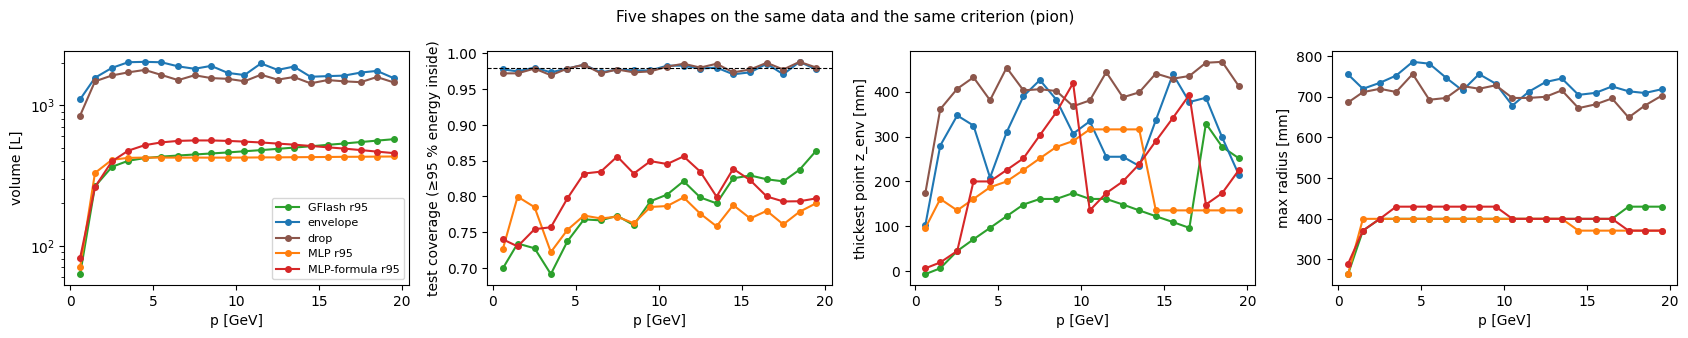

In [10]:
colors = {"GFlash r95": "tab:green", "envelope": "tab:blue", "drop": "tab:brown", "MLP r95": "tab:orange", "MLP-formula r95": "tab:red"}
fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
for name in [o for o in ORDER if o in set(CMP.formula)]:
    g = CMP[CMP.formula == name]
    for a_, col in zip(ax, ["V_L", "cov_test", "z_env", "r_max"]):
        a_.plot(g.p_mean, g[col], "o-", c=colors[name], label=name, ms=4)
for a_, lab in zip(ax, ["volume [L]", "test coverage (≥95 % energy inside)", "thickest point z_env [mm]", "max radius [mm]"]):
    a_.set(xlabel="p [GeV]", ylabel=lab)
ax[0].set_yscale("log"); ax[1].axhline(F_EV, c="k", lw=0.8, ls="--"); ax[0].legend(fontsize=8)
fig.suptitle("Five shapes on the same data and the same criterion (pion)", fontsize=11)
plt.tight_layout(); plt.show()

### 2D map with $(z', r)$ axes, in the same form as the comparison plot of 03

- **Background:** mean energy density of the training data in the given 1 GeV bin ($\log_{10}$, $r$ mirrored).
- **Green dotted:** GFlash $r_{95}$. **Blue:** envelope. **White:** drop. **Orange:** MLP $r_{95}$. **Red dashed:** distilled MLP-formula $r_{95}$.

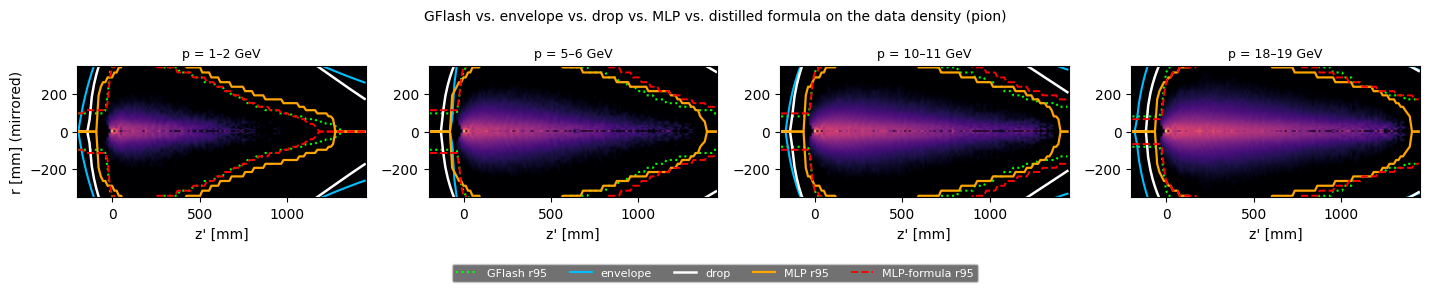

In [11]:
STYLE = {"GFlash r95": dict(c="lime", ls=":", lw=1.5), "envelope": dict(c="deepskyblue", lw=1.5), "drop": dict(c="white", lw=1.8),
         "MLP r95": dict(c="orange", lw=1.6), "MLP-formula r95": dict(c="red", ls="--", lw=1.4)}


def compare_map(sh, p_values=(1, 5, 10, 18), r_show=350, title=""):
    rc_ = RC.cpu().numpy()
    vol = np.exp(LOG_VOL.cpu().numpy())
    h = sh.hits()
    rs = np.linspace(-r_show, r_show, 121)
    fig, axes = plt.subplots(1, len(p_values), figsize=(3.6 * len(p_values), 2.8))
    for ax, p in zip(axes, p_values):
        b = int(p)
        m = (h.p >= b) & (h.p < b + 1)
        H, _, _ = np.histogram2d(h.z[m], h.r[m], bins=[z_edges, R_EDGES.cpu().numpy()], weights=h.w[m])
        d = H / max(h.ev[m].nunique(), 1) / vol
        img = np.log10(np.clip(np.stack([np.interp(np.abs(rs), rc_, row) for row in d], 1), 1e-14, None))
        ax.imshow(img, origin="lower", aspect="auto", extent=[Z_MIN, Z_MAX, -r_show, r_show], cmap="magma",
                  vmin=img.max() - 5, vmax=img.max())
        curves = {name: r95_of(mdl, b + 0.5) for name, mdl in MODELS.items()}
        if b in ENV:
            curves["envelope"] = envelope_r(zc, ENV[b])
        if b in DROP:
            curves["drop"] = drop_radius(zc, DROP[b])
        for name in ORDER:
            if name in curves:
                ax.plot(zc, curves[name], **STYLE[name]); ax.plot(zc, -curves[name], **STYLE[name])
        ax.set_ylim(-r_show, r_show); ax.set_title(f"p = {b}–{b + 1} GeV", fontsize=9); ax.set_xlabel("z' [mm]")
    axes[0].set_ylabel("r [mm] (mirrored)")
    handles = [plt.Line2D([], [], label=n, **STYLE[n]) for n in ORDER if n in set(CMP.formula)]
    fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=8, facecolor="0.3", labelcolor="w")
    fig.suptitle(title, fontsize=10)
    fig.tight_layout(rect=(0, 0.1, 1, 1))
    plt.show()


compare_map(data["train"], title="GFlash vs. envelope vs. drop vs. MLP vs. distilled formula on the data density (pion)")

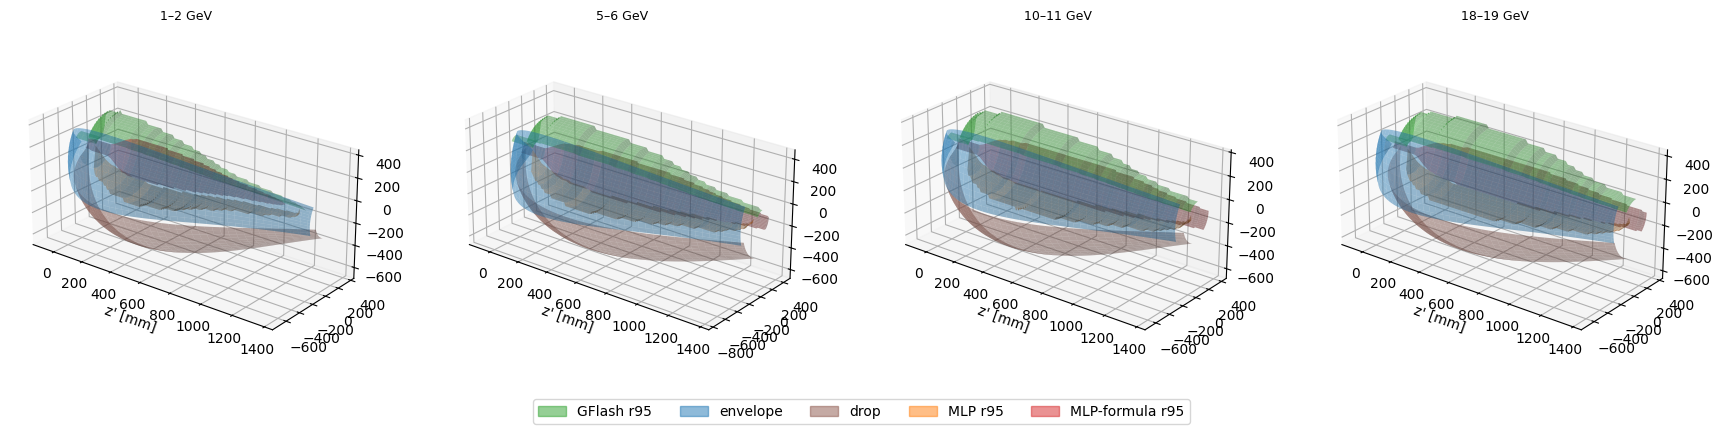

saved: comparison_5shapes.csv, mlp_architecture.csv


In [12]:
# the five bodies side by side in 3D: each body in its own sector, so all of them stay visible
show = [1, 5, 10, 18]
fig = plt.figure(figsize=(4.4 * len(show), 4.2))
for j, b in enumerate(show):
    ax_ = fig.add_subplot(1, len(show), j + 1, projection="3d")
    bodies = {name: r95_of(mdl, b + 0.5) for name, mdl in MODELS.items()}
    if b in ENV:
        bodies["envelope"] = envelope_r(zc, ENV[b])
    if b in DROP:
        bodies["drop"] = drop_radius(zc, DROP[b])
    names = [n for n in ORDER if n in bodies]
    for k, name in enumerate(names):
        f0 = 0.5 * np.pi + 1.5 * np.pi * k / len(names); f1 = 0.5 * np.pi + 1.5 * np.pi * (k + 1) / len(names)
        ax_.plot_surface(*revolve(zc, bodies[name], f0, f1, 12), color=colors[name], alpha=0.45, linewidth=0)
    ax_.set_xlim(-150, 1450); ax_.set_box_aspect((2.2, 1, 1)); ax_.view_init(elev=24, azim=-52)
    ax_.set_title(f"{b}–{b + 1} GeV", fontsize=9); ax_.set_xlabel("z' [mm]")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colors[n], alpha=0.5, label=n) for n in ORDER if n in set(CMP.formula)], loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()
CMP.to_csv(f"{OUT_DIR}/{particle}/comparison_5shapes.csv", index=False)
ARCH_TABLE.to_csv(f"{OUT_DIR}/{particle}/mlp_architecture.csv")
print("saved: comparison_5shapes.csv, mlp_architecture.csv")